In [1]:
# Adding any country coincidence options as inflated the dataset size, no longer good for .csv so switching to .hyper
# Python3 is required 
#
# pip install openpyxl
#
# The following should work fine for no Macbook M1 environments
# pip install tableauhyperapi
# wget https://downloads.tableau.com/tssoftware/tableauhyperapi-0.0.12514-py3-none-macosx_10_11_x86_64.whl
# pip install https://downloads.tableau.com/tssoftware/tableauhyperapi-0.0.12514-py3-none-macosx_10_11_x86_64.whl
#
# https://github.com/WillAyd/pantab
# pip install pantab

# Need to start the x86 emu version of python for the Tableau Hyper API to work correctly
# /usr/local/Cellar/ipython/7.22.0/bin/ipython notebook

In [1]:
import re
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tableauhyperapi as hyper
import pantab  # Requires tableauhyperapi - helper to move from pandas.DataFrame -> .hyper file
from datetime import date
sns.set()
sns.set_style('whitegrid')

In [2]:
# source_path = '/Users/jking/Documents/Education/Northeastern/Analytics BE/ALY2100/UN Voting/Source Data'
source_path = './source_data/'
source_file = f'{source_path}/NortheasternExport4.xlsx'
df = pd.read_excel(source_file, engine='openpyxl')

In [3]:
columns = ['ID', 'Code-NV', 'Code-Vote', 'Description1', 'Date', 'Vote-Summary', 'Committee', 'Description2',
          'Title', 'DocHistor', 'GAVote', 'CommitteeVote']

# https://research.un.org/en/digitallibrary/export
# Columns are MARC format (machine-readable cataloging)
# 191__a, 650__a - appear to be generic UN MARCs, identified under the 
#
# Column mapping and definitions taken from the voting manual:
# https://www.un.org/depts/dhl/unbisref_manual/voting/voting.htm
columns = {1: 'ID', '191__a': 'UNDocumentSymbol', '791__a': 'ResolutionSymbol', '245__a': 'TitleStatement', 
           992: 'ActionDate', 996: 'VoteNote', '793__a': 'CommitteeName', '991__c': 'AgendaTitle', 
           '991__d': 'AgendaSubject', '993__a': 'RelatedDocumentSymbols', 967: 'VotingInformation', 
           '650__a': 'TopicSubjects'}

In [4]:
df.rename(columns=columns, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14439 entries, 0 to 14438
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   ID                      14439 non-null  int64         
 1   UNDocumentSymbol        7356 non-null   object        
 2   ResolutionSymbol        7083 non-null   object        
 3   TitleStatement          14438 non-null  object        
 4   ActionDate              14431 non-null  datetime64[ns]
 5   VoteNote                9030 non-null   object        
 6   CommitteeName           7829 non-null   object        
 7   AgendaTitle             14428 non-null  object        
 8   AgendaSubject           14423 non-null  object        
 9   RelatedDocumentSymbols  14424 non-null  object        
 10  VotingInformation       1682 non-null   object        
 11  TopicSubjects           7297 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(10)
mem

In [5]:
# Illistrate the contents of the VotingInformation 
df[(df.VotingInformation.notnull())][['ID', 'VotingInformation']].head(3)

,ID,VotingInformation
372,422519,1; AFG; AFGHANISTAN; 2; ALB; ALBANIA; 3; DZA; ...
394,426217,1; AFG; Y; AFGHANISTAN; 2; ALB; Y; ALBANIA; 3;...
418,426984,1; AFG; AFGHANISTAN; 2; ALB; A; ALBANIA; 3; DZ...


In [6]:
def parse_voting_information(df):
    """
    Parse voting information form dataframe with ID and VotingInformation columns
    Returns: nested dictionary in the form {ID: {CountryCode: Vote}, ...}
    """
    votes_by_id = dict()
    cntry_to_cntry_name = dict()
    for index, row in df.iterrows():
        un_voting_id = row['ID']
        votes = row['VotingInformation']

        # Split the string into a list, changing elements at each numeric character instance
        vote_list = re.split(r'(\D+)', votes)
        # Reduce the list to only the character elements
        vote_list = [x for x in vote_list if not x.isnumeric()]
        
        votes = {}
        for vote in vote_list:
            vote_split = vote.split(';')
            if len(vote_split) > 1:
                country_code = vote_split[1].strip()
                # Avoid empty country code cases
                if len(country_code) > 0:
                    # This first case only applies to Zambia (last country)
                    # the only missing vote info while cntry is there
                    if len(vote_split) > 1 and len(vote_split) < 4:
                        votes[country_code] = np.NaN
                    # Zambia is the last country in the list and has no trailing space char
                    elif len(vote_split) == 4:
                        if vote_split[2].strip() in ['Y', 'N', 'A']:
                            votes[country_code] = vote_split[2].strip()
                            cntry_to_cntry_name[country_code] = vote_split[3].strip()
                    elif len(vote_split) >= 5:
                        votes[country_code] = vote_split[2].strip()
                        cntry_to_cntry_name[country_code] = vote_split[3].strip()
        votes_by_id[un_voting_id] = votes
    return votes_by_id, cntry_to_cntry_name

In [7]:
# Filter source data to only rows that include voting information values
ff = df[(df.VotingInformation.notnull())][['ID', 'VotingInformation']]\

# Split the combined country / vote string into parts by ID
res, cntry_to_cntry_name = parse_voting_information(df=ff)

# Confirm the resulting dict object has the same number of rows as the input frame
print(f'Frame row count: {df[df.VotingInformation.notnull()].shape[0]} | processed dict key count: {len(res.keys())}')

Frame row count: 1682 | processed dict key count: 1682


In [8]:
# Matrix of Country x ID of vote values Y, N and NaN (not attended)
xf = pd.DataFrame(res)
xf.head()

,422519,426217,426984,426989,426997,427081,427520,427521,427522,427523,...,3895476,3896178,3896179,3896180,3896181,3896182,3896183,3897076,3897077,3897078
DZA,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,...,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y
AND,Y,Y,Y,Y,A,Y,N,A,Y,A,...,Y,Y,Y,N,Y,Y,A,Y,Y,Y
AGO,Y,Y,Y,Y,Y,NaN,Y,Y,Y,Y,...,NaN,Y,Y,A,A,Y,A,Y,Y,Y
ATG,Y,Y,Y,Y,Y,A,Y,Y,Y,Y,...,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ARG,Y,Y,Y,Y,Y,Y,A,A,Y,A,...,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y


In [9]:
def score_votes(df, root_cntry='USA', target_cntry='CHN'):
    """
    Score votes according to the "voting coincidence" methodology
    Returns Pandas Series 
    """
    # Assign Root and Target country Series
    r = df.loc[root_cntry]
    t = df.loc[target_cntry]

    # Output Series is copy of the target country Series
    o = t.copy()

    # Apply the conditional logic to the arrays
    o.loc[r == t] = 1  # Same
    o.loc[r != t] = 0  # Opposite
    o.loc[(r.isin(['Y', 'N'])) & (t == 'A')] = .5  # Partial, either direction
    o.loc[(t.isin(['Y', 'N'])) & (r == 'A')] = .5  # Partial, either direction
    
    # For resolutions adopted by acclaim, the vote of every country is assinge "same" (=1) 
    # and calcualted accordingly, How to identify these cases?

    # Ensure that NaN (Absent) votes are correctly retained
    o.loc[t.isnull()] = np.NaN  # Absent
    return o

In [10]:
all_dat = []
for root_cntry in xf.index:
    dat = []
    # Iterate over all of the countries in the xf frame index, applying scoring to the row-wise series
    for target_cntry in xf.index:
        # Need to include USA as the output frame is used for total vote counts
        dat.append(score_votes(df=xf, root_cntry=root_cntry, target_cntry=target_cntry))

    # Recreate the frame with scores inplace of vote strings 
    nf = pd.DataFrame(dat)
    print(f'Coincidence Country: {root_cntry} Original voting frame shape: {xf.shape} | '
          f'scored vote frame shape: {nf.shape}')
    
    # Prepend the Coincidence Country to the multiindex
    nf = pd.concat({root_cntry: nf}, names=['CoincidenceCountry'])
    all_dat.append(nf)
nf = pd.concat(all_dat)

Coincidence Country: DZA Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: AND Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: AGO Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: ATG Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: ARG Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: ARM Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: AUS Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: AUT Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: AZE Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: BHR Original voting frame shape: (

Coincidence Country: PHL Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: POL Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: PRT Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: QAT Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: KOR Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: ROU Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: RUS Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SMR Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SAU Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SGP Original voting frame shape: (

Coincidence Country: LCA Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: VCT Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: WSM Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: STP Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SEN Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SLE Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SLB Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: LKA Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SUR Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: TJK Original voting frame shape: (

In [11]:
nf.loc['USA']

,422519,426217,426984,426989,426997,427081,427520,427521,427522,427523,...,3895476,3896178,3896179,3896180,3896181,3896182,3896183,3897076,3897077,3897078
DZA,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.5,0.5,0.5,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
AND,0.0,0.0,0.0,1.0,0.5,0.0,1.0,1.0,0.5,1.0,...,1.0,0.0,0.0,1.0,1.0,1.0,0.5,0.0,0.0,0.0
AGO,0.0,0.0,0.0,1.0,1.0,NaN,0.0,0.5,0.5,0.5,...,NaN,0.0,0.0,0.5,0.5,1.0,0.5,0.0,0.0,0.0
ATG,0.0,0.0,0.0,1.0,1.0,0.5,0.0,0.5,0.5,0.5,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ARG,0.0,0.0,0.0,1.0,1.0,0.0,0.5,1.0,0.5,1.0,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LBR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,0.0,0.0,NaN,1.0,1.0,NaN,0.0,0.0,0.0
IRQ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
SRB,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,0.0,0.0,0.0,NaN,NaN,0.5,0.0,0.0,0.0
MNE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,0.0,0.0,1.0,1.0,1.0,0.5,0.0,0.0,0.0


In [12]:
# Compute all time voting coincidence
coincidence_country = 'USA'
voting_coincidence = nf.loc[coincidence_country].T.sum().div(nf.loc[coincidence_country].T.count()).multiply(100).sort_values(ascending=False)
voting_coincidence

USA    100.000000
ISR     89.013999
FSM     78.992537
PLW     72.422062
MHL     71.024735
          ...    
ZWE     17.981889
IRN     17.917448
CUB     17.746820
SYR     16.911765
PRK     15.689540
Length: 195, dtype: float64

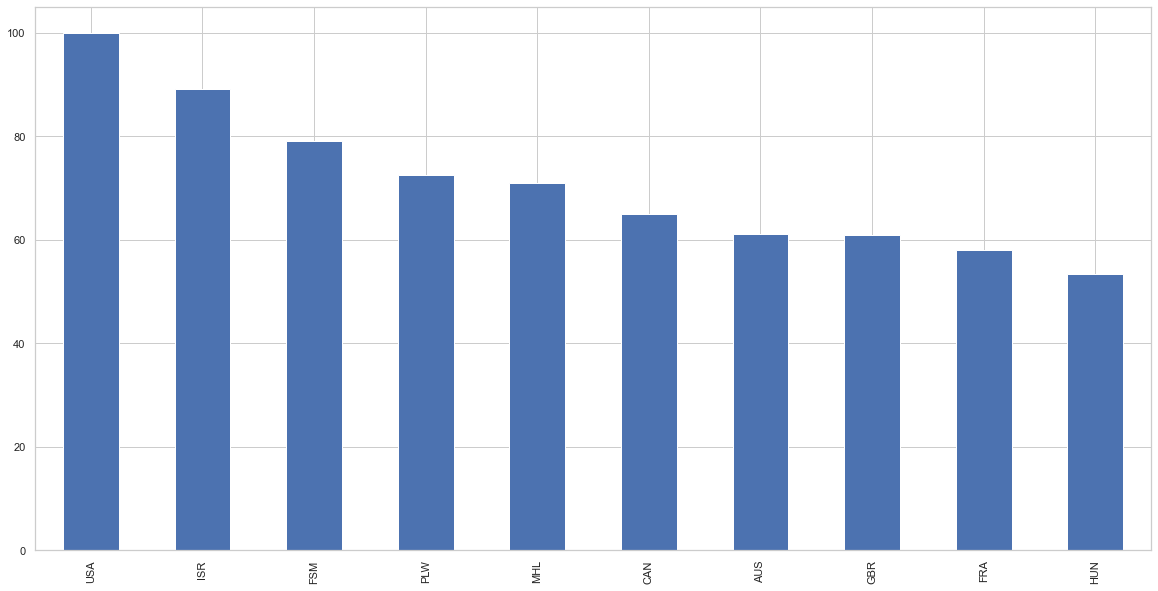

In [13]:
# Plot the top 10 country by voting coincidence with US
ax = voting_coincidence.sort_values(ascending=False).head(10).plot(kind='bar', figsize=(20, 10))

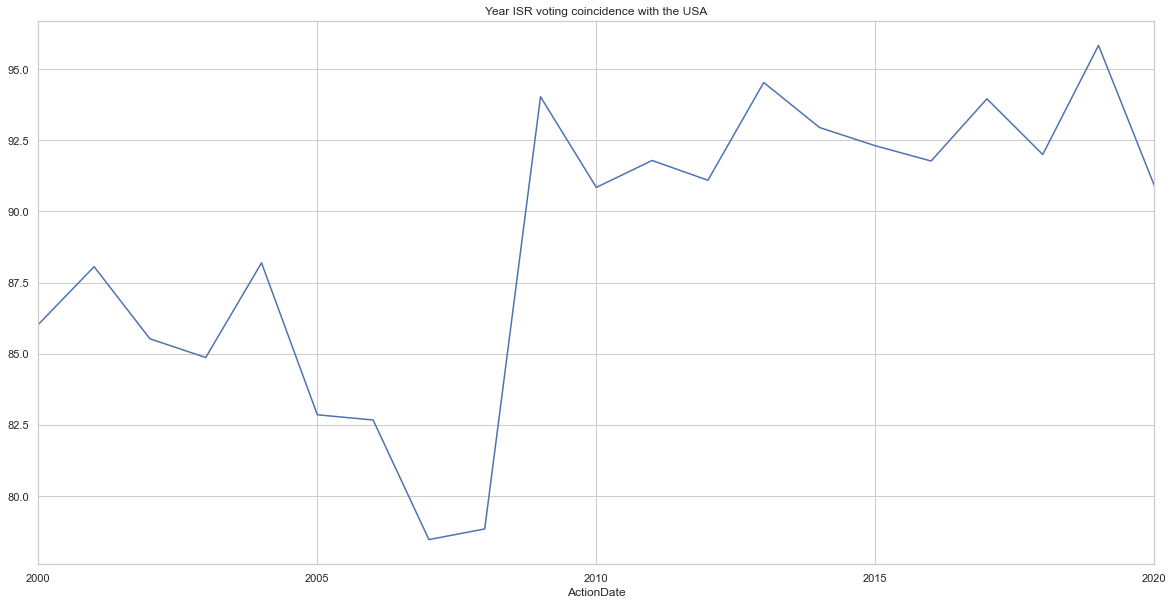

In [14]:
zf = nf.loc[coincidence_country].T.merge(df[df.ActionDate.notnull()], how='left', left_index=True, right_on='ID')
grp = zf.set_index('ActionDate')['ISR'].groupby(pd.Grouper(freq='Y'))
_ = grp.sum().div(grp.count()).multiply(100).plot(
    figsize=(20, 10), title=f'Year ISR voting coincidence with the {coincidence_country}')

In [15]:
##################################################
# Begin cateogry mapping
# Categories taken from GA Votes Working Document.xlsx - Top level Sub level description tab
# Sheet downloaded as csv
# https://docs.google.com/spreadsheets/d/1cYxtXgdAD2MuCOkzGeTNW7v8TaGeer6d/edit#gid=1743910634
# Load the category data exported from the csv export
# source_path = '/Users/jking/Documents/Education/Northeastern/Analytics BE/ALY2100/UN Voting/Source Data'
source_path = './source_data/'
source_file = f'{source_path}/GA Votes Working Document.xlsx - Top level Sub level description.csv'
cf = pd.read_csv(source_file, usecols=[0,1], names=['ID', 'Description']).dropna().reset_index(drop=True)
# Ascending sort order by ID is enforced here since we're forward filling values
cf.sort_values('ID', inplace=True)
cf.head()

,ID,Description
0,1.0,Israeli-Palestinian Issues
1,2.0,Decolonization
2,2.1,Statements of Principle
3,2.2,Geographic/regional cases
4,3.0,Human Rights


In [16]:
# Slice the category ID into top / sub level values
# Derive the TopLevel value based on the ID value (whole numbers only)
cf['TopLevel'] = np.NaN
cf.loc[cf['ID'].apply(float.is_integer), 'TopLevel'] = cf.loc[cf['ID'].apply(float.is_integer), 'ID']
cf['TopLevel'].ffill(inplace=True)

# Derive the SubLevel value based on the ID value (only the floats, indicating the level)
cf['SubLevel'] = np.NaN
cf.loc[cf['ID'].apply(float.is_integer) == False, 'SubLevel'] = cf.loc[cf['ID'].apply(float.is_integer) == False, 'ID']

# Generate top / sub level descriptions to be used as a heirarchy in Tableau
cf['TopLevelDescription'] = np.NaN
cf.loc[cf['ID'].apply(float.is_integer), 'TopLevelDescription'] = cf.loc[cf['ID'].apply(float.is_integer), 'Description']
cf['TopLevelDescription'].ffill(inplace=True)

cf['SubLevelDescription'] = np.NaN
cf.loc[cf['ID'].apply(float.is_integer) == False, 'SubLevelDescription'] = cf.loc[cf['ID'].apply(float.is_integer) == False, 'Description']
cf['SubLevelDescription'].fillna(cf['TopLevelDescription'], inplace=True)

# Add the level numbers as the prefix to the description strings
cf['TopLevelDescription'] = cf['TopLevel'].astype(str) + ' ' + cf['TopLevelDescription']
cf['SubLevelDescription'] = cf['SubLevel'].fillna(cf.TopLevel).astype(str) + ' ' + cf['SubLevelDescription']

# Top the ID & Description columns to avoid confusion
cf.drop(columns=['ID', 'Description'], inplace=True)
# Replace NaN sub level values with top level values, there is only one sub level and the NaNs cause join issues
cf['SubLevel'].fillna(cf['TopLevel'], inplace=True)

In [17]:
cf.head()

,TopLevel,SubLevel,TopLevelDescription,SubLevelDescription
0,1.0,1.0,1.0 Israeli-Palestinian Issues,1.0 Israeli-Palestinian Issues
1,2.0,2.0,2.0 Decolonization,2.0 Decolonization
2,2.0,2.1,2.0 Decolonization,2.1 Statements of Principle
3,2.0,2.2,2.0 Decolonization,2.2 Geographic/regional cases
4,3.0,3.0,3.0 Human Rights,3.0 Human Rights


In [18]:
# Load the vote info x category data - exported from GDrive
source_file = f'{source_path}/GA Votes Working Document.xlsx - Top Level Sub level.csv'
vote_info_to_cats = pd.read_csv(source_file)
vote_info_to_cats.columns
columns = {'Resolution Code': 'ResolutionCode', 'Top Level': 'TopLevel', 'Sub-level': 'SubLevel'}
vote_info_to_cats = vote_info_to_cats.rename(columns=columns)[columns.values()]

# Now merge the vote info x category codes
print(df.shape)
df1 = pd.merge(df[df.ResolutionSymbol.notnull()], vote_info_to_cats, how='left', left_on='ResolutionSymbol', right_on='ResolutionCode')
df2 = pd.merge(df[df.UNDocumentSymbol.notnull()], vote_info_to_cats, how='left', left_on='UNDocumentSymbol', right_on='ResolutionCode')
df = pd.concat([df1, df2])
print(df.shape)

# Replace NaN sub level values with top level values, there is only one sub level and the NaNs cause join issues
df['SubLevel'].fillna(df['TopLevel'], inplace=True)

(14439, 12)
(14439, 15)


In [ ]:
zf = nf.loc[coincidence_country].T.merge(
    df.merge(cf, how='left', on=['TopLevel', 'SubLevel'])[['ID', 'SubLevel', 'SubLevelDescription']], 
                how='left', left_index=True, right_on='ID')
grp = zf[zf.SubLevel.notnull()].drop(columns=['ID', 'SubLevel']).groupby('SubLevelDescription')
_ = grp.sum().div(grp.count()).multiply(100).T.mean().plot(
    kind='bar', figsize=(20, 10), title=f'Total voting coincidence with the {coincidence_country} by category')

In [ ]:
# Final data reformatting of vote scores for Tableau
nf_out = nf.unstack().unstack().reset_index().rename(columns={'level_0': 'ID', 'level_1': 'CountryCode', 0: 'Score'})

# Add country names to the original df frame, which ultimately is saved as VoteInfo
nf_out['CountryName'] = nf_out['CountryCode'].map(cntry_to_cntry_name)
nf_out['CoincidenceCountryName'] = nf_out['CoincidenceCountry'].map(cntry_to_cntry_name)

In [ ]:
# Save the dataframes in csv format, pre-formatted for Tableau
# df.to_csv('VoteInfo.csv')
# nf.unstack().unstack().reset_index().rename(columns={'level_0': 'ID', 'level_1': 'CountryCode', 0: 'Score'}).to_csv('VoteScores.csv', index=False)
# cf.to_csv('Categories.csv', index=False)

# Export all 3 frames as tables within a single .hyper file
# CommitteeName comtains 4 rows with the integer value of 2, this is causing issues with pantab type detection
df['CommitteeName'] = df['CommitteeName'].map({2: 'Two'})
un_voting_date = {'VoteInfo': df, 'VoteScores': nf_out, 'Categories': cf}
pantab.frames_to_hyper(dict_of_frames=un_voting_date, database='UNVotingData.hyper')

In [ ]:
df[(df.TopLevel.isnull()) & (df.VotingInformation.notnull())].ResolutionSymbol

In [ ]:
##################################################
# Begin GDP data processing
#
# GDP data by country, year taken from the UN stats site below
# https://unstats.un.org/unsd/snaama/Downloads
# GDP and its breakdown at current prices in US Dollars
#   - All countries for all years - sorted alphabetically

In [ ]:
source_path = './source_data/'
source_file = f'{source_path}/Download-GDPcurrent-USD-countries.xlsx'
gdp = pd.read_excel(source_file, engine='openpyxl', skiprows=2)
gdp = gdp[gdp.IndicatorName == 'Gross Domestic Product (GDP)']
gdp.head()

In [ ]:
coincidence_country = 'USA'
zf = nf.loc[coincidence_country].T.merge(df[df.ActionDate.notnull()], how='left', left_index=True, right_on='ID')
zf['Year'] = zf['ActionDate'].dt.year.fillna(0).astype(int)
##
grp = zf[zf.Year != 0].groupby('Year')[nf.loc['USA'].index]
pf = grp.sum().div(grp.count()).multiply(100)
pf

In [ ]:
# Reverse the map
cntry_name_to_cntry = {v:k for k, v in cntry_to_cntry_name.items()}

# Mannual map of GDP country names to UN Voting country names
xmap = {'D.P.R. of Korea': "DEMOCRATIC PEOPLE'S REPUBLIC OF KOREA"}
gdp.loc[gdp['Country'].isin(xmap.keys()), 'Country'] = gdp.loc[gdp['Country'].isin(xmap.keys())]['Country'].map(xmap)

gdp['Cntry'] = gdp['Country'].str.upper().map(cntry_name_to_cntry)
print(f"Could not map {gdp[gdp['Cntry'].isnull()].shape[0]} countries...")

In [ ]:
gf = gdp.set_index('Cntry').drop(columns=['CountryID', 'Country', 'IndicatorName']).T
gf.index = gf.index.astype(int)
# Compute mean GDP in USD by country for the same year range as we have UN Voting data
gf = gf.loc[pf.index.min():pf.index.max()].mean()
gf.name = 'GDP'  # Set series name
gf.sort_values(ascending=False).head()

In [ ]:
# Average of yearly voting coincidence with USA across all countries
pf.mean().sort_values(ascending=False)

In [ ]:
cdf = pd.DataFrame({'USAVotingCoincidence': pf.mean()}).join(gf).dropna()
cdf = cdf[cdf.index != 'USA']

In [ ]:
_ = cdf.plot(x='USAVotingCoincidence', y='GDP', kind='scatter', figsize=(10, 10))

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans

In [ ]:
mms = MinMaxScaler()
mms.fit(cdf)
dat_trans = mms.transform(cdf)

ssd  = []
for k in range(1,15):
    km = KMeans(n_clusters=k)
    km = km.fit(dat_trans)
    ssd.append(km.inertia_)
    

_ = pd.DataFrame(index=K, data=ssd).plot(figsize=(8, 8), marker='x', ylabel='Sum of squared distances', 
                                         xlabel='k', legend=False, title='Elbow method for optimal k')

In [ ]:
sc = StandardScaler()
sc.fit(cdf)
X = sc.transform(cdf)

km = KMeans(init="random", n_clusters=4, n_init=10, max_iter=300, random_state=42)
km.fit(X)
labels = kmeans.labels_
centroids = kmeans.cluster_centers_

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
X = sc.inverse_transform(X)
centroids = sc.inverse_transform(kmeans.cluster_centers_)
plt.scatter(X[:,0], X[:,1], c=labels, cmap='viridis')
plt.scatter(x=centroids[:,0], y=centroids[:,1], color='red', alpha=.8)

In [ ]:
# Add the cluster labels to the original frame
cdf['Cluster'] = labels
cdf.reset_index().rename(columns={'index': 'CountryCode'}).to_csv('./CountryClusters.csv')